In [ ]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Paste your key : ")

!pip install -q --upgrade kaggle
!mkdir -p /content/largest
!kaggle datasets download liuxu77/largest -p /content/largest

In [ ]:
!mkdir -p /content/data
!unzip -o /content/largest/largest.zip ca_his_raw_2020.h5 ca_his_raw_2021.h5 ca_meta.csv ca_rn_adj.npy -d /content/data
!ls -lh /content/data

Archive:  /content/largest/largest.zip
  inflating: /content/data/ca_his_raw_2020.h5  
  inflating: /content/data/ca_his_raw_2021.h5  
  inflating: /content/data/ca_meta.csv  
  inflating: /content/data/ca_rn_adj.npy  
total 15G
-rw-r--r-- 1 root root 6.8G Jun 13  2023 ca_his_raw_2020.h5
-rw-r--r-- 1 root root 6.8G Jun 13  2023 ca_his_raw_2021.h5
-rw-r--r-- 1 root root 558K Jun 13  2023 ca_meta.csv
-rw-r--r-- 1 root root 565M Jun 13  2023 ca_rn_adj.npy


In [ ]:
import numpy as np, pandas as pd, h5py
D = "/content/data"

meta = pd.read_csv(f"{D}/ca_meta.csv")
print("meta:", meta.shape); print(meta.columns.tolist()); print(meta.head(3))

sd = meta[meta["District"] == 11]
print("SD sensors:", len(sd))
print("SD rows contiguous in meta?", bool((np.diff(sd.index) == 1).all()))

adj = np.load(f"{D}/ca_rn_adj.npy", mmap_mode="r")   # memory-mapped, not loaded into RAM
print("adj:", adj.shape, adj.dtype)

with h5py.File(f"{D}/ca_his_raw_2020.h5", "r") as f:
    f.visititems(lambda name, obj: print(name, obj))

meta: (8600, 10)
['ID', 'Lat', 'Lng', 'District', 'County', 'Fwy', 'Lanes', 'Type', 'Direction', 'ID2']
       ID        Lat         Lng  District      County   Fwy  Lanes      Type  \
0  317802  38.389811 -121.479587         3  Sacramento  I5-N      2  Mainline   
1  312134  38.412564 -121.484319         3  Sacramento  I5-N      2  Mainline   
2  312133  38.428630 -121.487657         3  Sacramento  I5-N      3  Mainline   

  Direction  ID2  
0         N    0  
1         N    1  
2         N    2  
SD sensors: 716
SD rows contiguous in meta? True
adj: (8600, 8600) float64
t <HDF5 group "/t" (4 members)>
t/axis0 <HDF5 dataset "axis0": shape (8600,), type "|S9">
t/axis1 <HDF5 dataset "axis1": shape (105408,), type "<i8">
t/block0_items <HDF5 dataset "block0_items": shape (8600,), type "|S9">
t/block0_values <HDF5 dataset "block0_values": shape (105408, 8600), type "<f8">


In [ ]:
import numpy as np, pandas as pd, h5py
D = "/content/data"

meta = pd.read_csv(f"{D}/ca_meta.csv")
sd = meta[meta["District"] == 11]
sd_ids = sd["ID"].astype(str).values            # SD sensor IDs, in metadata order
sd_pos = sd.index.values                        # their row positions (also adjacency indices)
assert len(sd_ids) == 716

def load_sd(year):
    with h5py.File(f"{D}/ca_his_raw_{year}.h5", "r") as f:
        cols = np.char.decode(f["t/axis0"][:].astype("S"))         # all 8600 column IDs
        # flow-file column order must equal metadata order
        assert (cols == meta["ID"].astype(str).values).all(), "column order differs from metadata!"
        i0, i1 = sd_pos[0], sd_pos[-1] + 1                          # contiguous slice
        vals = f["t/block0_values"][:, i0:i1]                       # (T, 716)
        ts = pd.to_datetime(f["t/axis1"][:])                        # int64 -> datetime
    assert (cols[i0:i1] == sd_ids).all()
    return pd.DataFrame(vals, index=ts, columns=sd_ids)

df = pd.concat([load_sd(2020), load_sd(2021)])
print("shape:", df.shape)
print("range:", df.index.min(), "->", df.index.max())
print("index monotonic/unique:", df.index.is_monotonic_increasing, df.index.is_unique)
print("5-min regular:", (df.index.to_series().diff().dropna() == pd.Timedelta("5min")).all())
print("expected rows (366+365 days * 288):", (366 + 365) * 288)

# ---- diagnostics for missing values and units ----
v = df.values
print("\nNaN fraction overall:", np.isnan(v).mean().round(5))
print("sensors with any NaN:", int(np.isnan(v).any(0).sum()), "| all-NaN sensors:", int(np.isnan(v).all(0).sum()))
print("zero fraction overall:", (v == 0).mean().round(5))
print("min / max / mean / median:", np.nanmin(v), np.nanmax(v), np.nanmean(v).round(2), np.nanmedian(v))
print("share of non-integer values:", (np.nan_to_num(v) % 1 != 0).mean().round(5))
print(df.iloc[:3, :4])

df.to_pickle(f"{D}/sd_5min_2020_2021.pkl")   # cache so you don't re-read the 7 GB files

shape: (210528, 716)
range: 2020-01-01 00:00:00 -> 2021-12-31 23:55:00
index monotonic/unique: True True
5-min regular: True
expected rows (366+365 days * 288): 210528

NaN fraction overall: 0.05066
sensors with any NaN: 716 | all-NaN sensors: 19
zero fraction overall: 0.00267
min / max / mean / median: 0.0 999.0 217.66 182.0
share of non-integer values: 0.0
                     1114091  1118333  1118348  1114720
2020-01-01 00:00:00     78.0     49.0     42.0     47.0
2020-01-01 00:05:00     47.0     21.0     19.0     28.0
2020-01-01 00:10:00     43.0     24.0     22.0     37.0


values == 999: 155 | >= 900: 33148
15-min shape: (70176, 716) | expected: (70176, 716)

NaN fraction (15-min): 0.0508
per-sensor NaN fraction:
 count    716.000
mean       0.051
std        0.203
min        0.000
25%        0.000
50%        0.000
75%        0.000
max        1.000
dtype: float64
all-NaN sensors: 19

number of gaps: 6719
share of gaps <= 4 steps (1 h): 0.909
share of gaps <= 96 steps (1 day): 0.996
longest gap (steps): 62016
share of all gap-steps lying in gaps > 1 day: 0.981
timestamps with >50% of sensors missing: 12


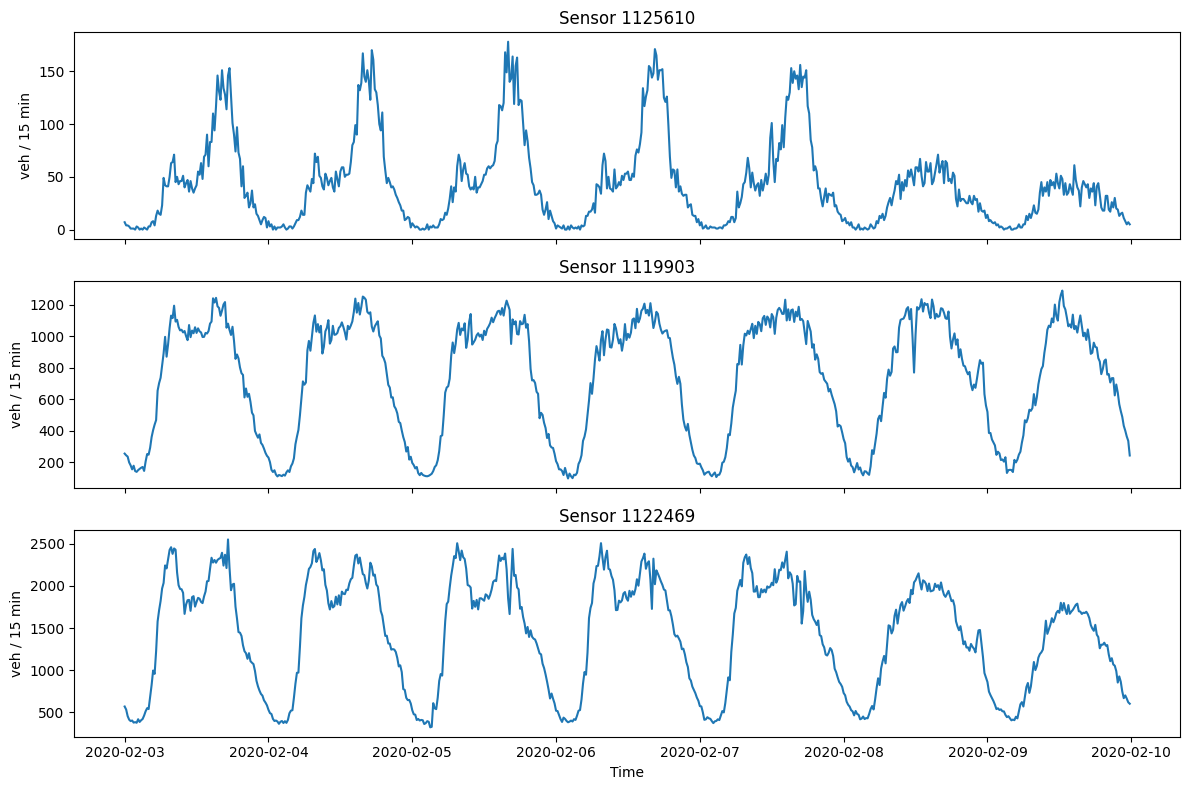

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
D = "/content/data"
df = pd.read_pickle(f"{D}/sd_5min_2020_2021.pkl")

# the 999 question
v5 = df.values
print("values == 999:", int((v5 == 999).sum()), "| >= 900:", int((v5 >= 900).sum()))

# resample: sum of the 3 five-minute counts; any NaN inside the window -> NaN
df15 = df.resample("15min").sum(min_count=3)
print("15-min shape:", df15.shape, "| expected:", (731 * 96, 716))
df15.to_pickle(f"{D}/sd_15min_raw.pkl")

# missing-value diagnostics on the 15-min data
v = df15.values
nanmask = np.isnan(v)
print("\nNaN fraction (15-min):", nanmask.mean().round(4))
per_sensor = nanmask.mean(0)
print("per-sensor NaN fraction:\n", pd.Series(per_sensor).describe().round(3))
print("all-NaN sensors:", int((per_sensor == 1).sum()))

def run_lengths(m):
    m = np.concatenate([[0], m.astype(int), [0]])
    d = np.diff(m)
    return np.where(d == -1)[0] - np.where(d == 1)[0]

gaps = np.concatenate([run_lengths(nanmask[:, j]) for j in range(v.shape[1]) if per_sensor[j] < 1])
print("\nnumber of gaps:", len(gaps))
print("share of gaps <= 4 steps (1 h):", (gaps <= 4).mean().round(3))
print("share of gaps <= 96 steps (1 day):", (gaps <= 96).mean().round(3))
print("longest gap (steps):", gaps.max())
print("share of all gap-steps lying in gaps > 1 day:", (gaps[gaps > 96].sum() / gaps.sum()).round(3))

per_time = nanmask.mean(1)
print("timestamps with >50% of sensors missing:", int((per_time > 0.5).sum()))

# plot: 3 sensors (low / median / high flow) with complete data, one week (Mon-Sun)
week = df15.loc["2020-02-03":"2020-02-09"]
full = week.columns[week.isna().sum() == 0]
means = week[full].mean().sort_values()
picks = [means.index[0], means.index[len(means) // 2], means.index[-1]]
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, s in zip(axes, picks):
    ax.plot(week.index, week[s]); ax.set_ylabel("veh / 15 min"); ax.set_title(f"Sensor {s}")
axes[-1].set_xlabel("Time")
plt.tight_layout(); plt.savefig("q3a_week_plot.png", dpi=150)
plt.show()

In [ ]:
import numpy as np, pandas as pd
D = "/content/data"
df15 = pd.read_pickle(f"{D}/sd_15min_raw.pkl")

splits = {"train": ("2020-01-01 00:00", "2020-12-31 23:45"),
          "val":   ("2021-01-01 00:00", "2021-03-31 23:45"),
          "test":  ("2021-04-01 00:00", "2021-12-31 23:45")}
MAX_FILL = 4   # steps = 1 hour

def fill_short_gaps(a, max_len):
    """Linearly interpolate interior NaN gaps of length <= max_len (per sensor)."""
    out = a.copy()
    T, N = a.shape
    for j in range(N):
        x = a[:, j]
        nan = np.isnan(x)
        if not nan.any() or nan.all():
            continue
        d = np.diff(np.concatenate([[0], nan.astype(int), [0]]))
        for s, e in zip(np.where(d == 1)[0], np.where(d == -1)[0]):   # e is exclusive
            if s > 0 and e < T and (e - s) <= max_len:
                out[s:e, j] = np.interp(np.arange(s, e), [s - 1, e], [x[s - 1], x[e]])
    return out

arrays, times = {}, {}
for name, (a, b) in splits.items():
    seg = df15.loc[a:b]
    before = np.isnan(seg.values)
    filled = fill_short_gaps(seg.values, MAX_FILL)
    after = np.isnan(filled)
    arrays[name] = filled.astype(np.float32)
    times[name] = seg.index.values.astype("datetime64[m]").astype(np.int64)
    print(f"{name:5s} shape={filled.shape} | NaN before={before.mean():.4f} after={after.mean():.4f} "
          f"| sensors with no data in split: {int(after.all(0).sum())}")

np.savez_compressed(f"{D}/sd_15min_splits.npz",
                    **{f"X_{k}": v for k, v in arrays.items()},
                    **{f"t_{k}": v for k, v in times.items()},
                    sensor_ids=df15.columns.values.astype(str))
print("saved")

train shape=(35136, 716) | NaN before=0.0411 after=0.0409 | sensors with no data in split: 19
val   shape=(8640, 716) | NaN before=0.0609 after=0.0604 | sensors with no data in split: 43
test  shape=(26400, 716) | NaN before=0.0603 after=0.0602 | sensors with no data in split: 43
saved


nodes: 716
nonzero entries (incl. diagonal): 18035
nonzero diagonal entries: 716
nonzero off-diagonal entries (directed edges): 17319
weights: min/max of nonzero: 0.010001835317713963 1.0 | any NaN: False | any negative: False
edges from SD rows to sensors outside SD: 11

symmetric: False | entries with A[i,j] != A[j,i]: 21022 | max |A - A.T|: 0.9999998696620915
edges present in one direction only: 3711

out-degree: min/mean/median/max: 0 24.19 20.0 70
in-degree : min/mean/median/max: 0 24.19 19.0 68
isolated sensors (no in or out edges): 3


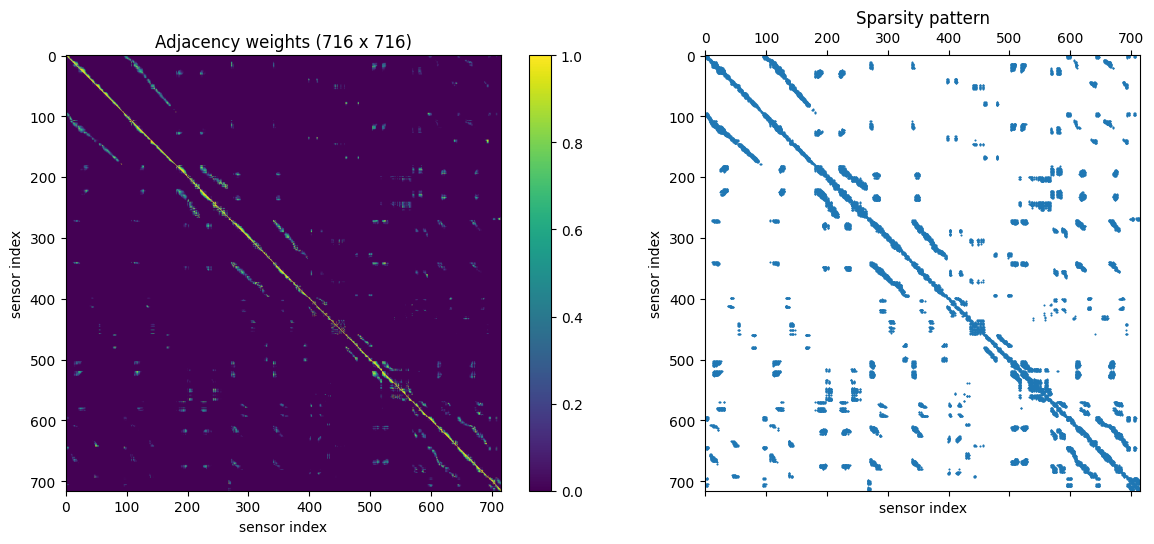

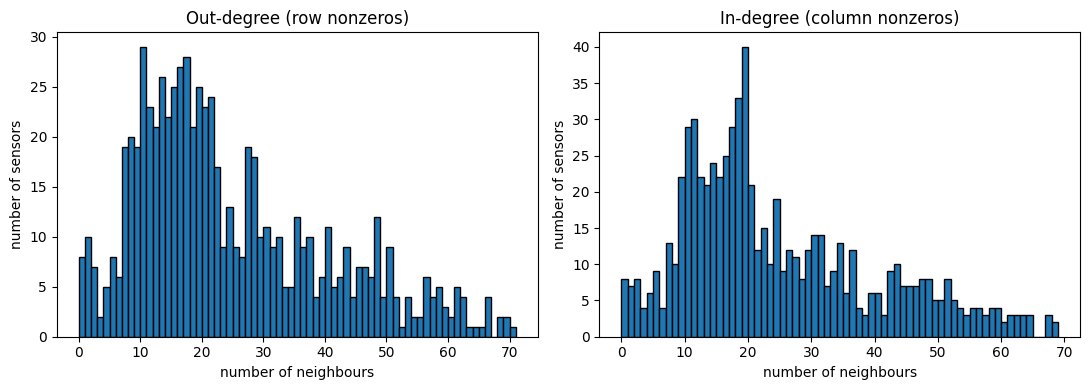

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
D = "/content/data"

meta = pd.read_csv(f"{D}/ca_meta.csv")
sd = meta[meta["District"] == 11]
i0, i1 = sd.index[0], sd.index[-1] + 1
Afull = np.load(f"{D}/ca_rn_adj.npy", mmap_mode="r")
A = np.array(Afull[i0:i1, i0:i1])                      # (716, 716)

# ordering check: adjacency rows/cols must follow the same sensor order as the flow tensor
ids = np.load(f"{D}/sd_15min_splits.npz")["sensor_ids"]
assert (ids == sd["ID"].astype(str).values).all()
np.save(f"{D}/A_sd.npy", A)

# 1) nodes and edges
off = A.copy(); np.fill_diagonal(off, 0)
print("nodes:", A.shape[0])
print("nonzero entries (incl. diagonal):", int((A != 0).sum()))
print("nonzero diagonal entries:", int((np.diag(A) != 0).sum()))
print("nonzero off-diagonal entries (directed edges):", int((off != 0).sum()))
print("weights: min/max of nonzero:", A[A != 0].min(), A[A != 0].max(), "| any NaN:", bool(np.isnan(A).any()), "| any negative:", bool((A < 0).any()))
print("edges from SD rows to sensors outside SD:", int((Afull[i0:i1, :i0] != 0).sum() + (Afull[i0:i1, i1:] != 0).sum()))

# 2) symmetry
sym = np.allclose(A, A.T)
asym_pairs = int(((A != A.T)).sum())
print("\nsymmetric:", sym, "| entries with A[i,j] != A[j,i]:", asym_pairs, "| max |A - A.T|:", np.abs(A - A.T).max())
print("edges present in one direction only:", int(((off != 0) & (off.T == 0)).sum()))

# 4) neighbours per sensor
out_deg = (off != 0).sum(1)      # j such that A[i,j] != 0
in_deg  = (off != 0).sum(0)
print("\nout-degree: min/mean/median/max:", out_deg.min(), out_deg.mean().round(2), np.median(out_deg), out_deg.max())
print("in-degree : min/mean/median/max:", in_deg.min(), in_deg.mean().round(2), np.median(in_deg), in_deg.max())
print("isolated sensors (no in or out edges):", int(((out_deg == 0) & (in_deg == 0)).sum()))

# 3) heatmap + sparsity pattern
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
im = ax[0].imshow(A, cmap="viridis", aspect="equal"); ax[0].set_title("Adjacency weights (716 x 716)")
fig.colorbar(im, ax=ax[0], fraction=0.046)
ax[1].spy(A, markersize=0.5); ax[1].set_title("Sparsity pattern")
for a in ax: a.set_xlabel("sensor index"); a.set_ylabel("sensor index")
plt.tight_layout(); plt.savefig("q3b_adjacency.png", dpi=150); plt.show()

# 4) degree distribution
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(out_deg, bins=range(0, out_deg.max() + 2), edgecolor="k"); ax[0].set_title("Out-degree (row nonzeros)")
ax[1].hist(in_deg, bins=range(0, in_deg.max() + 2), edgecolor="k"); ax[1].set_title("In-degree (column nonzeros)")
for a in ax: a.set_xlabel("number of neighbours"); a.set_ylabel("number of sensors")
plt.tight_layout(); plt.savefig("q3b_degree.png", dpi=150); plt.show()

In [ ]:
import numpy as np, pandas as pd
D = "/content/data"
A = np.load(f"{D}/A_sd.npy")
meta = pd.read_csv(f"{D}/ca_meta.csv"); sd = meta[meta.District == 11].reset_index(drop=True)
off = A.copy(); np.fill_diagonal(off, 0)
r, c = np.nonzero(off)
same_fwy = (sd.Fwy.values[r] == sd.Fwy.values[c]).mean()
print("edges between sensors on the same Fwy/direction label:", round(same_fwy, 3))

edges between sensors on the same Fwy/direction label: 0.223


sensor idx 33, ID 1126411, I5-N, San Diego
one-hop: 20 | two-hop only: 53 | total within 2 hops: 73
median distance (km): one-hop 2.0 | two-hop only 4.96
     ID  Fwy  weight   km
1114805 I5-N   0.953 0.98
1114035 I5-N   0.824 1.94
1108547 I5-N   0.758 2.32
1118707 I5-N   0.634 2.95
1114806 I5-S   0.460 0.97
1126426 I5-S   0.264 0.24
1108711 I5-S   0.204 1.93
1108693 I5-S   0.124 3.30
1115356 I8-E   0.082 1.56
1117818 I5-S   0.059 2.51

mean correlation with sensor:  one-hop nan | two-hop only 0.919 | all others 0.885
within 1 hops: mean 25 nodes (3.5% of the graph)
within 2 hops: mean 68 nodes (9.5% of the graph)
within 3 hops: mean 117 nodes (16.3% of the graph)
within 4 hops: mean 173 nodes (24.1% of the graph)
within 5 hops: mean 231 nodes (32.3% of the graph)
within 6 hops: mean 290 nodes (40.4% of the graph)


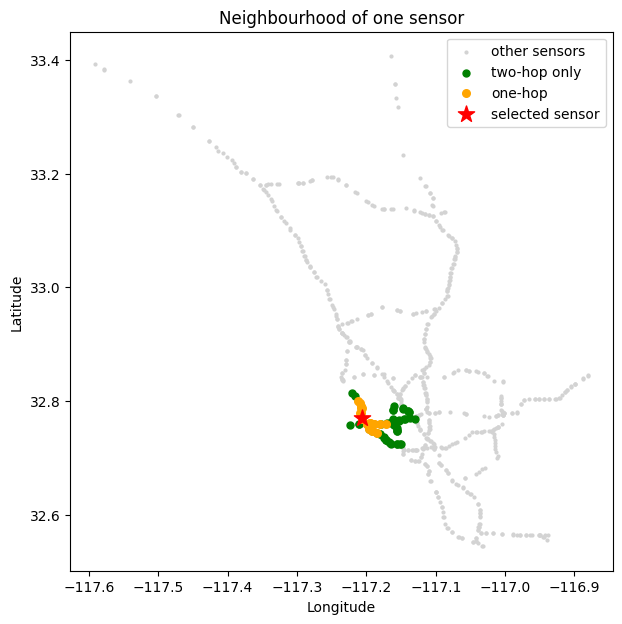

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
D = "/content/data"
A = np.load(f"{D}/A_sd.npy"); Z = np.load(f"{D}/sd_15min_splits.npz")
Xtr = Z["X_train"]; ids = Z["sensor_ids"]
meta = pd.read_csv(f"{D}/ca_meta.csv"); sd = meta[meta.District == 11].reset_index(drop=True)

B = (A != 0); np.fill_diagonal(B, False)            # N(i) = {j : A_ij != 0}, excluding i itself
out_deg = B.sum(1)
valid = np.all([~np.isnan(Z[f"X_{s}"]).all(0) for s in ["train", "val", "test"]], axis=0)
i = np.where((out_deg == 20) & valid)[0][0]

one = np.where(B[i])[0]
two_all = np.where(B[i] | B[one].any(0))[0]
two_only = np.setdiff1d(two_all, np.append(one, i))
print(f"sensor idx {i}, ID {ids[i]}, {sd.Fwy[i]}, {sd.County[i]}")
print("one-hop:", len(one), "| two-hop only:", len(two_only), "| total within 2 hops:", len(one) + len(two_only))

def hav(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    a = np.sin((lat2-lat1)*p/2)**2 + np.cos(lat1*p)*np.cos(lat2*p)*np.sin((lon2-lon1)*p/2)**2
    return 12742 * np.arcsin(np.sqrt(a))
dist = hav(sd.Lat[i], sd.Lng[i], sd.Lat.values, sd.Lng.values)
print("median distance (km): one-hop", np.median(dist[one]).round(2), "| two-hop only", np.median(dist[two_only]).round(2))
print(pd.DataFrame({"ID": ids[one], "Fwy": sd.Fwy.values[one], "weight": A[i, one].round(3), "km": dist[one].round(2)})
      .sort_values("weight", ascending=False).head(10).to_string(index=False))

# do neighbours carry similar traffic? (training data only)
corr = pd.DataFrame(Xtr).corrwith(pd.Series(Xtr[:, i]))
others = np.setdiff1d(np.arange(len(ids)), np.concatenate([[i], two_all]))
print("\nmean correlation with sensor:  one-hop", corr.values[one].mean().round(3),
      "| two-hop only", np.nanmean(corr.values[two_only]).round(3),
      "| all others", np.nanmean(corr.values[others]).round(3))

# receptive-field growth with depth
n = len(ids); R = np.eye(n, dtype=bool); Bf = B.astype(np.float32)
for k in range(1, 7):
    R = R | ((R.astype(np.float32) @ Bf) > 0)
    print(f"within {k} hops: mean {R.sum(1).mean():.0f} nodes ({R.sum(1).mean()/n:.1%} of the graph)")

plt.figure(figsize=(7, 7))
plt.scatter(sd.Lng, sd.Lat, s=4, c="lightgray", label="other sensors")
plt.scatter(sd.Lng[two_only], sd.Lat[two_only], s=25, c="green", label="two-hop only")
plt.scatter(sd.Lng[one], sd.Lat[one], s=30, c="orange", label="one-hop")
plt.scatter(sd.Lng[i], sd.Lat[i], s=150, c="red", marker="*", label="selected sensor")
plt.legend(); plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.title("Neighbourhood of one sensor")
plt.savefig("q3c_neighbourhood.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
Xtr = Z["X_train"]
t = np.arange(Xtr.shape[0])
slot = ((t // 96 + 2) % 7) * 96 + t % 96          # 2020-01-01 was a Wednesday; 96 steps/day
df = pd.DataFrame(Xtr)
res = df - df.groupby(slot).transform("mean")      # remove weekly profile
for name, X in [("raw", df), ("residual", res)]:
    c = X.corrwith(X[i]).values
    print(name, "| one-hop", np.nanmean(c[one]).round(3),
          "| two-hop only", np.nanmean(c[two_only]).round(3),
          "| all others", np.nanmean(c[others]).round(3))

raw | one-hop 0.918 | two-hop only 0.919 | all others 0.885
residual | one-hop 0.854 | two-hop only 0.851 | all others 0.755


Question 4(a)

In [ ]:
import numpy as np, torch
D = "/content/data"
Z = np.load(f"{D}/sd_15min_splits.npz")
T_IN, T_OUT = 8, 4
arr = {s: Z[f"X_{s}"] for s in ["train", "val", "test"]}

# normalisation statistics: training split, observed values only
MU, SD = float(np.nanmean(arr["train"])), float(np.nanstd(arr["train"]))
print(f"train mean = {MU:.2f}, std = {SD:.2f}")

class Windows:
    """Sliding windows within one split. Window s: inputs rows s..s+7, targets rows s+8..s+11."""
    def __init__(self, a, mu=MU, sd=SD):
        a = torch.from_numpy(a)
        self.mask = ~torch.isnan(a)                          # observed entries
        self.x = torch.nan_to_num((a - mu) / sd, nan=0.0)    # normalised; NaN -> train mean
        self.y = torch.nan_to_num(a, nan=0.0)                # original units (use with mask)
        self.n = a.shape[0] - (T_IN + T_OUT) + 1             # number of windows
    def batch(self, idx):
        ix = idx[:, None] + torch.arange(T_IN)
        iy = idx[:, None] + T_IN + torch.arange(T_OUT)
        return self.x[ix].unsqueeze(-1), self.y[iy].unsqueeze(-1), self.mask[iy].unsqueeze(-1)
        # shapes: (B, 8, 716, 1), (B, 4, 716, 1), (B, 4, 716, 1)

W = {s: Windows(a) for s, a in arr.items()}

# ---- sanity checks ----
for s, w in W.items():
    x, y, m = w.batch(torch.arange(w.n))
    print(f"{s:5s} windows={w.n:6d}  x={tuple(x.shape)}  y={tuple(y.shape)}  "
          f"targets observed={m.float().mean():.4f}")
    del x, y, m

# window alignment test on a random window
w, a = W["val"], arr["val"]; s0 = 1234
x, y, m = w.batch(torch.tensor([s0]))
assert np.allclose(y[0, :, :, 0].numpy()[m[0, :, :, 0].numpy()], a[s0 + 8: s0 + 12][~np.isnan(a[s0 + 8: s0 + 12])])
assert w.n == a.shape[0] - 11

# ---- masked metrics (original units) ----
def masked_mae(pred, y, m):  return ((pred - y).abs() * m).sum() / m.sum()
def masked_rmse(pred, y, m): return torch.sqrt((((pred - y) ** 2) * m).sum() / m.sum())

# ---- reference: persistence baseline on validation (repeat the last observed input) ----
w = W["val"]; idx = torch.arange(w.n)
_, y, m = w.batch(idx)
last = w.y[idx + T_IN - 1]                         # (n, N) raw last input
ok = w.mask[idx + T_IN - 1]                        # last input was observed
pred = last[:, None, :, None].expand_as(y)
m2 = m & ok[:, None, :, None]
for h in range(T_OUT):
    print(f"persistence val MAE, horizon {h+1} (+{15*(h+1)} min): "
          f"{masked_mae(pred[:, h], y[:, h], m2[:, h].float()):.2f}")
print("persistence val MAE overall:", float(masked_mae(pred, y, m2.float())),
      "| RMSE:", float(masked_rmse(pred, y, m2.float())))

train mean = 607.21, std = 483.52
train windows= 35125  x=(35125, 8, 716, 1)  y=(35125, 4, 716, 1)  targets observed=0.9591
val   windows=  8629  x=(8629, 8, 716, 1)  y=(8629, 4, 716, 1)  targets observed=0.9396
test  windows= 26389  x=(26389, 8, 716, 1)  y=(26389, 4, 716, 1)  targets observed=0.9398
persistence val MAE, horizon 1 (+15 min): 49.29
persistence val MAE, horizon 2 (+30 min): 70.67
persistence val MAE, horizon 3 (+45 min): 91.62
persistence val MAE, horizon 4 (+60 min): 112.93
persistence val MAE overall: 81.12574768066406 | RMSE: 124.91710662841797


In [ ]:
import time, json, copy, os, platform, random
import numpy as np, torch, torch.nn as nn

SEED = 42
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", dev, "| torch", torch.__version__, "| CPU cores:", os.cpu_count(),
      "|", platform.processor() or platform.machine(),
      "|", torch.cuda.get_device_name(0) if dev.type == "cuda" else "no GPU")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

# windows on the chosen device; batch() must build its aranges on the same device
def _batch(self, idx):
    ar = torch.arange(T_IN + T_OUT, device=idx.device)
    ix = idx[:, None] + ar[:T_IN]
    iy = idx[:, None] + ar[T_IN:]
    return self.x[ix].unsqueeze(-1), self.y[iy].unsqueeze(-1), self.mask[iy].unsqueeze(-1)
Windows.batch = _batch
for w in W.values():
    w.x, w.y, w.mask = w.x.to(dev), w.y.to(dev), w.mask.to(dev)

def build_Ahat(A):
    """Row-normalised directed adjacency: D^-1 (A_offdiag + I)."""
    A = A.astype(np.float64).copy(); np.fill_diagonal(A, 0)
    At = A + np.eye(len(A))
    Ah = At / At.sum(1, keepdims=True)
    assert np.allclose(Ah.sum(1), 1)
    return Ah.astype(np.float32)

class STGNN(nn.Module):
    def __init__(self, Ahat=None, d=32, hid=64, t_in=T_IN, t_out=T_OUT, skip=True):
        super().__init__()
        self.skip = skip
        self.enc = nn.Sequential(
            nn.Conv1d(1, d, 3), nn.ReLU(),
            nn.Conv1d(d, d, 3), nn.ReLU(),
            nn.Conv1d(d, d, t_in - 4), nn.ReLU())
        self.Wg = nn.Linear(d, d)
        self.head = nn.Sequential(nn.Linear(d, hid), nn.ReLU(), nn.Linear(hid, t_out))
        if Ahat is not None: self.register_buffer("Ahat", Ahat)
        else: self.Ahat = None
    def forward(self, x):
        B, T, N, _ = x.shape
        z = x.squeeze(-1).permute(0, 2, 1).reshape(B * N, 1, T)
        z = self.enc(z).view(B, N, -1)                      # Z
        g = self.Wg(z)
        if self.Ahat is not None:
            g = torch.matmul(self.Ahat, g)                  # A_hat Z W_g
        h = torch.relu(g)
        if self.skip: h = z + h                             # skip connection
        return self.head(h).permute(0, 2, 1).unsqueeze(-1)


@torch.no_grad()
def evaluate(model, w, bs=256):
    model.eval()
    ae = torch.zeros(T_OUT, device=dev); se = torch.zeros(T_OUT, device=dev); cnt = torch.zeros(T_OUT, device=dev)
    for s in range(0, w.n, bs):
        idx = torch.arange(s, min(s + bs, w.n), device=dev)
        x, y, m = w.batch(idx); m = m.float()
        pred = model(x) * SD + MU                      # back to vehicles / 15 min
        ae += ((pred - y).abs() * m).sum((0, 2, 3))
        se += (((pred - y) ** 2) * m).sum((0, 2, 3))
        cnt += m.sum((0, 2, 3))
    return dict(mae=float(ae.sum() / cnt.sum()), rmse=float((se.sum() / cnt.sum()).sqrt()),
                mae_h=(ae / cnt).cpu().tolist())

def run(name, Ahat, d=32, hid=64, epochs=20, patience=4, bs=64, lr=1e-3, build=None):
    set_seed(SEED)
    model = (build() if build else STGNN(Ahat, d, hid)).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(SEED)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"[{name}] parameters: {n_params}")
    best, best_state, bad = float("inf"), None, 0
    if dev.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for ep in range(1, epochs + 1):
        model.train(); tl, nb = 0.0, 0
        perm = torch.randperm(W["train"].n, generator=g).to(dev)
        for s in range(0, len(perm), bs):
            x, y, m = W["train"].batch(perm[s:s + bs]); m = m.float()
            loss = ((model(x) - (y - MU) / SD).abs() * m).sum() / m.sum()   # masked MAE (normalised)
            opt.zero_grad(); loss.backward(); opt.step()
            tl += loss.item(); nb += 1
        v = evaluate(model, W["val"])
        print(f"[{name}] epoch {ep:2d} | train {tl/nb:.4f} | val MAE {v['mae']:.2f} RMSE {v['rmse']:.2f} | {time.perf_counter()-t0:.0f}s")
        if v["mae"] < best - 1e-3:
            best, bad, best_state = v["mae"], 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience: break
    if dev.type == "cuda": torch.cuda.synchronize()
    train_time = time.perf_counter() - t0
    model.load_state_dict(best_state)
    val, test = evaluate(model, W["val"]), evaluate(model, W["test"])
    torch.save(best_state, f"{D}/model_{name}.pt")
    return dict(val_mae=val["mae"], val_rmse=val["rmse"], test_mae=test["mae"], test_rmse=test["rmse"],
                test_mae_by_horizon=test["mae_h"], train_time_s=train_time, epochs_run=ep, params=n_params)

device: cuda | torch 2.14.1+cu130 | CPU cores: 2 | x86_64 | Tesla T4


In [ ]:
A = np.load(f"{D}/A_sd.npy")
Ahat = torch.tensor(build_Ahat(A)).to(dev)

results = {}
results["Temporal-only"] = run("temporal_only", None)
results["STGNN-fixed"]   = run("stgnn_fixed", Ahat)

for k, r in results.items():
    print(f"\n{k}: val MAE {r['val_mae']:.2f} RMSE {r['val_rmse']:.2f} | test MAE {r['test_mae']:.2f} RMSE {r['test_rmse']:.2f} "
          f"| {r['train_time_s']:.0f}s, {r['epochs_run']} epochs | test MAE by horizon {np.round(r['test_mae_by_horizon'], 1)}")
json.dump(results, open(f"{D}/results_q4.json", "w"), indent=2)

[temporal_only] parameters: 10788
[temporal_only] epoch  1 | train 0.1655 | val MAE 60.56 RMSE 97.64 | 24s
[temporal_only] epoch  2 | train 0.1213 | val MAE 60.35 RMSE 97.13 | 46s
[temporal_only] epoch  3 | train 0.1199 | val MAE 59.40 RMSE 95.66 | 70s
[temporal_only] epoch  4 | train 0.1185 | val MAE 58.30 RMSE 94.29 | 94s
[temporal_only] epoch  5 | train 0.1181 | val MAE 58.33 RMSE 94.69 | 117s
[temporal_only] epoch  6 | train 0.1174 | val MAE 57.95 RMSE 93.43 | 139s
[temporal_only] epoch  7 | train 0.1171 | val MAE 57.70 RMSE 93.38 | 164s
[temporal_only] epoch  8 | train 0.1168 | val MAE 57.98 RMSE 93.72 | 186s
[temporal_only] epoch  9 | train 0.1167 | val MAE 59.05 RMSE 94.37 | 210s
[temporal_only] epoch 10 | train 0.1161 | val MAE 58.13 RMSE 92.61 | 235s
[temporal_only] epoch 11 | train 0.1157 | val MAE 58.59 RMSE 93.63 | 260s
[stgnn_fixed] parameters: 10788
[stgnn_fixed] epoch  1 | train 0.1660 | val MAE 58.54 RMSE 95.68 | 25s
[stgnn_fixed] epoch  2 | train 0.1183 | val MAE 59.85

Question 5

In [ ]:
class AdaptiveSTGNN(STGNN):
    def __init__(self, N=716, de=10, d=32, hid=64):
        super().__init__(None, d, hid, skip=True)
        self.E1 = nn.Parameter(torch.randn(N, de))
        self.E2 = nn.Parameter(torch.randn(N, de))
    def adjacency(self):
        return torch.softmax(torch.relu(self.E1 @ self.E2.T), dim=1)   # row-wise softmax
    def forward(self, x):
        B, T, N, _ = x.shape
        z = x.squeeze(-1).permute(0, 2, 1).reshape(B * N, 1, T)
        z = self.enc(z).view(B, N, -1)
        g = torch.matmul(self.adjacency(), self.Wg(z))   # recomputed every batch so gradients reach E1, E2
        h = z + torch.relu(g)
        return self.head(h).permute(0, 2, 1).unsqueeze(-1)

results = json.load(open(f"{D}/results_q4.json"))
results["STGNN-adaptive"] = run("stgnn_adaptive", None, build=lambda: AdaptiveSTGNN(de=10))
r = results["STGNN-adaptive"]
print(f"\nSTGNN-adaptive: val MAE {r['val_mae']:.2f} RMSE {r['val_rmse']:.2f} | test MAE {r['test_mae']:.2f} "
      f"RMSE {r['test_rmse']:.2f} | {r['train_time_s']:.0f}s, {r['epochs_run']} epochs | "
      f"test MAE by horizon {np.round(r['test_mae_by_horizon'], 1)}")
json.dump(results, open(f"{D}/results_q5.json", "w"), indent=2)

[stgnn_adaptive] parameters: 25108
[stgnn_adaptive] epoch  1 | train 0.1646 | val MAE 56.48 RMSE 92.25 | 26s
[stgnn_adaptive] epoch  2 | train 0.1119 | val MAE 55.08 RMSE 88.93 | 50s
[stgnn_adaptive] epoch  3 | train 0.1049 | val MAE 51.53 RMSE 83.39 | 76s
[stgnn_adaptive] epoch  4 | train 0.1019 | val MAE 49.57 RMSE 80.40 | 100s
[stgnn_adaptive] epoch  5 | train 0.0992 | val MAE 50.09 RMSE 80.23 | 126s
[stgnn_adaptive] epoch  6 | train 0.0975 | val MAE 48.17 RMSE 78.64 | 152s
[stgnn_adaptive] epoch  7 | train 0.0963 | val MAE 46.94 RMSE 76.97 | 176s
[stgnn_adaptive] epoch  8 | train 0.0959 | val MAE 46.91 RMSE 76.91 | 202s
[stgnn_adaptive] epoch  9 | train 0.0945 | val MAE 47.41 RMSE 76.88 | 228s
[stgnn_adaptive] epoch 10 | train 0.0941 | val MAE 46.13 RMSE 75.45 | 254s
[stgnn_adaptive] epoch 11 | train 0.0931 | val MAE 46.25 RMSE 75.44 | 279s
[stgnn_adaptive] epoch 12 | train 0.0928 | val MAE 45.51 RMSE 74.44 | 303s
[stgnn_adaptive] epoch 13 | train 0.0922 | val MAE 45.26 RMSE 73.94 

row sums all 1: True
self-weight: median 0.0
effective neighbours per row: min/median/max = 1.2 15.4 90.8
share of row mass in the 20 largest entries: median 0.843


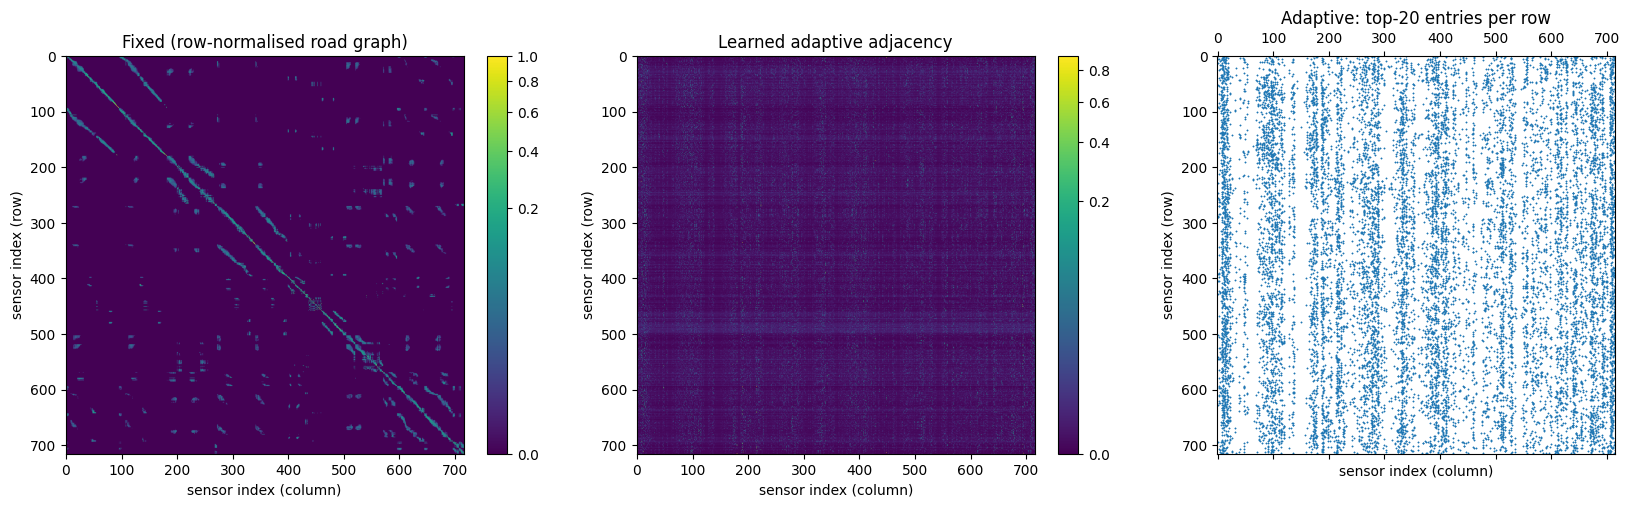

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm

m = AdaptiveSTGNN(de=10).to(dev)
m.load_state_dict(torch.load(f"{D}/model_stgnn_adaptive.pt"))
A_adp = m.adjacency().detach().cpu().numpy()
np.save(f"{D}/A_adaptive.npy", A_adp)

print("row sums all 1:", np.allclose(A_adp.sum(1), 1))
print("self-weight: median", np.median(np.diag(A_adp)).round(3))
eff = 1 / (A_adp ** 2).sum(1)                       # effective number of neighbours per row
print("effective neighbours per row: min/median/max =", eff.min().round(1), np.median(eff).round(1), eff.max().round(1))
top20 = np.sort(A_adp, axis=1)[:, -20:].sum(1)
print("share of row mass in the 20 largest entries: median", np.median(top20).round(3))

topk_mask = np.zeros_like(A_adp, dtype=bool)
topk_mask[np.arange(716)[:, None], np.argsort(-A_adp, axis=1)[:, :20]] = True

Afix = build_Ahat(np.load(f"{D}/A_sd.npy"))
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a_, M, t in [(ax[0], Afix, "Fixed (row-normalised road graph)"), (ax[1], A_adp, "Learned adaptive adjacency")]:
    im = a_.imshow(M, cmap="viridis", norm=PowerNorm(0.3, vmin=0, vmax=M.max()))
    a_.set_title(t); fig.colorbar(im, ax=a_, fraction=0.046)
ax[2].spy(topk_mask, markersize=0.4); ax[2].set_title("Adaptive: top-20 entries per row")
for a_ in ax: a_.set_xlabel("sensor index (column)"); a_.set_ylabel("sensor index (row)")
plt.tight_layout(); plt.savefig("q5b_adjacency.png", dpi=150); plt.show()

Question 6(b)

In [ ]:
import numpy as np, pandas as pd
D = "/content/data"; N, K = 716, 20
A_adp = np.load(f"{D}/A_adaptive.npy"); A_road = np.load(f"{D}/A_sd.npy")
Xtr = np.load(f"{D}/sd_15min_splits.npz")["X_train"]
meta = pd.read_csv(f"{D}/ca_meta.csv"); sd = meta[meta.District == 11].reset_index(drop=True)

road = A_road != 0; np.fill_diagonal(road, False)
off = ~np.eye(N, dtype=bool)
Wk = A_adp.copy(); np.fill_diagonal(Wk, -1)                      # exclude self-loops from top-k
learned = np.zeros((N, N), bool)
learned[np.arange(N)[:, None], np.argsort(-Wk, axis=1)[:, :K]] = True

def hav(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    a = np.sin((lat2 - lat1) * p / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2
    return 12742 * np.arcsin(np.sqrt(a))
lat, lng = sd.Lat.values, sd.Lng.values
dist = hav(lat[:, None], lng[:, None], lat[None, :], lng[None, :])
same_fwy = sd.Fwy.values[:, None] == sd.Fwy.values[None, :]

t = np.arange(Xtr.shape[0]); slot = ((t // 96 + 2) % 7) * 96 + t % 96
df = pd.DataFrame(Xtr); res = df - df.groupby(slot).transform("mean")
C = res.corr().values                                             # residual correlation, training data only

print(f"{'edge set':16s} {'edges':>7s} {'median km':>10s} {'same Fwy':>9s} {'mean resid corr':>16s}")
for name, M in [("road edges", road), ("learned top-20", learned), ("all pairs", off)]:
    print(f"{name:16s} {M.sum():7d} {np.median(dist[M]):10.2f} {same_fwy[M].mean():9.3f} {np.nanmean(C[M]):16.3f}")

print("\nshare of learned top-20 edges that are road edges:", ((learned & road).sum() / learned.sum()).round(3),
      "| chance (road density):", (road.sum() / off.sum()).round(3))
print("share of road edges recovered by learned top-20:", ((learned & road).sum() / road.sum()).round(3),
      "| chance:", (learned.sum() / off.sum()).round(3))
print("learned edges whose reverse is also in the top-20:", ((learned & learned.T).sum() / learned.sum()).round(3))

indeg = learned.sum(0); srt = np.sort(indeg)[::-1]
print("\nhub structure: top-10 column in-degrees:", srt[:10])
print("sensors needed to cover 50% of learned edges:", int(np.searchsorted(np.cumsum(srt) / srt.sum(), 0.5)) + 1,
      "| sensors never selected:", int((indeg == 0).sum()))
hub = np.argsort(-indeg)[:5]
print(sd.loc[hub, ["ID", "Fwy", "County"]].assign(selected_by=indeg[hub]).to_string(index=False))
mean_flow = df.mean().values
print("mean flow: top-30 hubs", np.nanmean(mean_flow[np.argsort(-indeg)[:30]]).round(0), "| all sensors", np.nanmean(mean_flow).round(0))

eff = 1 / (A_adp ** 2).sum(1); dead = np.isnan(Xtr).all(0)
print("\neffective neighbours, median: sensors with no training data", np.median(eff[dead]).round(1),
      "| others", np.median(eff[~dead]).round(1), "| rows 465-500:", np.median(eff[465:501]).round(1))
print("indices of the 19 sensors with no training data:", np.where(dead)[0])

edge set           edges  median km  same Fwy  mean resid corr
road edges         17319       2.37     0.223            0.732
learned top-20     14320      23.13     0.090            0.689
all pairs         511940      23.02     0.070            0.675

share of learned top-20 edges that are road edges: 0.04 | chance (road density): 0.034
share of road edges recovered by learned top-20: 0.033 | chance: 0.028
learned edges whose reverse is also in the top-20: 0.031

hub structure: top-10 column in-degrees: [111  99  94  93  89  86  85  83  78  78]
sensors needed to cover 50% of learned edges: 128 | sensors never selected: 160
     ID    Fwy    County  selected_by
1123287 I905-W San Diego          111
1118735   I5-N San Diego           99
1114205   I5-N San Diego           94
1126526 I905-W San Diego           93
1126722  I15-N San Diego           89
mean flow: top-30 hubs 566.0 | all sensors 605.0

effective neighbours, median: sensors with no training data 8.1 | others 15.5 | rows 465-5

In [ ]:
class HybridSTGNN(AdaptiveSTGNN):
    def __init__(self, Afix, N=716, de=10, d=32, hid=64):
        super().__init__(N, de, d, hid)
        self.register_buffer("Afix", Afix)
        self.alpha_logit = nn.Parameter(torch.zeros(()))        # alpha = sigmoid(0) = 0.5 at start
    def alpha(self): return torch.sigmoid(self.alpha_logit)
    def adjacency(self):
        Aad = torch.softmax(torch.relu(self.E1 @ self.E2.T), dim=1)
        return self.alpha() * self.Afix + (1 - self.alpha()) * Aad

Ahat = torch.tensor(build_Ahat(np.load(f"{D}/A_sd.npy"))).to(dev)
results = json.load(open(f"{D}/results_q5.json"))
results["STGNN-hybrid"] = run("stgnn_hybrid", None, build=lambda: HybridSTGNN(Ahat))
r = results["STGNN-hybrid"]
print(f"\nSTGNN-hybrid: val MAE {r['val_mae']:.2f} RMSE {r['val_rmse']:.2f} | test MAE {r['test_mae']:.2f} "
      f"RMSE {r['test_rmse']:.2f} | {r['train_time_s']:.0f}s, {r['epochs_run']} epochs | "
      f"test MAE by horizon {np.round(r['test_mae_by_horizon'], 1)}")

m = HybridSTGNN(Ahat).to(dev); m.load_state_dict(torch.load(f"{D}/model_stgnn_hybrid.pt"))
print("learned alpha (weight on the road graph):", round(m.alpha().item(), 3))
json.dump(results, open(f"{D}/results_q5.json", "w"), indent=2)

[stgnn_hybrid] parameters: 25109
[stgnn_hybrid] epoch  1 | train 0.1647 | val MAE 56.85 RMSE 93.37 | 24s
[stgnn_hybrid] epoch  2 | train 0.1128 | val MAE 55.81 RMSE 90.25 | 48s
[stgnn_hybrid] epoch  3 | train 0.1071 | val MAE 52.00 RMSE 84.84 | 74s
[stgnn_hybrid] epoch  4 | train 0.1034 | val MAE 50.24 RMSE 81.75 | 98s
[stgnn_hybrid] epoch  5 | train 0.1007 | val MAE 50.13 RMSE 80.92 | 123s
[stgnn_hybrid] epoch  6 | train 0.0985 | val MAE 48.62 RMSE 79.44 | 149s
[stgnn_hybrid] epoch  7 | train 0.0972 | val MAE 47.46 RMSE 77.62 | 174s
[stgnn_hybrid] epoch  8 | train 0.0965 | val MAE 47.56 RMSE 77.71 | 198s
[stgnn_hybrid] epoch  9 | train 0.0945 | val MAE 47.40 RMSE 76.87 | 223s
[stgnn_hybrid] epoch 10 | train 0.0941 | val MAE 46.06 RMSE 75.08 | 248s
[stgnn_hybrid] epoch 11 | train 0.0930 | val MAE 45.98 RMSE 74.89 | 274s
[stgnn_hybrid] epoch 12 | train 0.0928 | val MAE 45.62 RMSE 74.47 | 300s
[stgnn_hybrid] epoch 13 | train 0.0919 | val MAE 45.15 RMSE 73.48 | 324s
[stgnn_hybrid] epoch 1

Question 6(a)

        Model Adjacency  Params  Val MAE  Val RMSE  Test MAE  Test RMSE  Train time (s)  Epochs
Temporal-only      None   10788    57.70     93.38     65.93     104.20          259.71      11
        STGNN     Fixed   10788    52.41     84.77     60.79      95.87          506.74      20
        STGNN  Adaptive   25108    44.57     72.64     53.17      83.92          501.19      20
        STGNN    Hybrid   25109    44.36     72.22     53.47      84.39          500.36      20
\begin{tabular}{llrrrrrrr}
\toprule
Model & Adjacency & Params & Val MAE & Val RMSE & Test MAE & Test RMSE & Train time (s) & Epochs \\
\midrule
Temporal-only & None & 10788 & 57.70 & 93.38 & 65.93 & 104.20 & 259.71 & 11 \\
STGNN & Fixed & 10788 & 52.41 & 84.77 & 60.79 & 95.87 & 506.74 & 20 \\
STGNN & Adaptive & 25108 & 44.57 & 72.64 & 53.17 & 83.92 & 501.19 & 20 \\
STGNN & Hybrid & 25109 & 44.36 & 72.22 & 53.47 & 84.39 & 500.36 & 20 \\
\bottomrule
\end{tabular}

sensors: [np.str_('1108741'), np.str_('1126864'), np

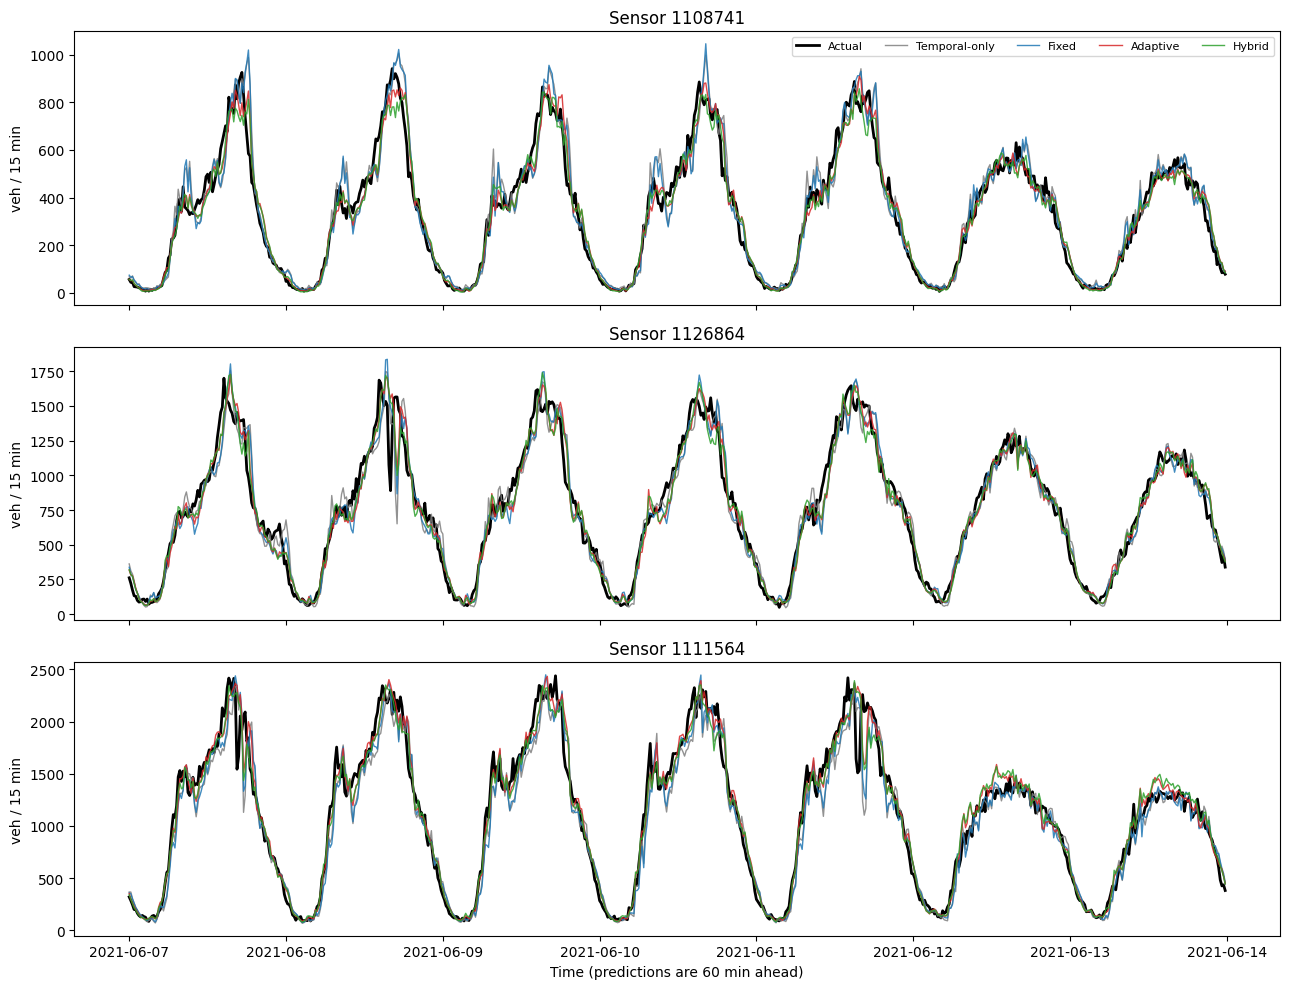

1108741 {'Temporal-only': 48.4, 'Fixed': 45.1, 'Adaptive': 34.7, 'Hybrid': 34.3}
1126864 {'Temporal-only': 88.1, 'Fixed': 80.0, 'Adaptive': 69.8, 'Hybrid': 69.5}
1111564 {'Temporal-only': 127.1, 'Fixed': 115.7, 'Adaptive': 86.2, 'Hybrid': 88.4}


In [ ]:
import json, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
D = "/content/data"

# ---- results table ----
res = json.load(open(f"{D}/results_q5.json"))
adj = {"Temporal-only": "None", "STGNN-fixed": "Fixed", "STGNN-adaptive": "Adaptive", "STGNN-hybrid": "Hybrid"}
tbl = pd.DataFrame([{"Model": "Temporal-only" if k == "Temporal-only" else "STGNN", "Adjacency": a,
                     "Params": res[k]["params"], "Val MAE": res[k]["val_mae"], "Val RMSE": res[k]["val_rmse"],
                     "Test MAE": res[k]["test_mae"], "Test RMSE": res[k]["test_rmse"],
                     "Train time (s)": res[k]["train_time_s"], "Epochs": res[k]["epochs_run"]}
                    for k, a in adj.items()])
print(tbl.round(2).to_string(index=False))
tbl.to_csv(f"{D}/results_table.csv", index=False)
print(tbl.to_latex(index=False, float_format="%.2f"))

# ---- load the four trained models ----
models = {"Temporal-only": STGNN(None), "Fixed": STGNN(Ahat),
          "Adaptive": AdaptiveSTGNN(de=10), "Hybrid": HybridSTGNN(Ahat)}
ckpt = {"Temporal-only": "temporal_only", "Fixed": "stgnn_fixed", "Adaptive": "stgnn_adaptive", "Hybrid": "stgnn_hybrid"}
for k, m in models.items():
    m.load_state_dict(torch.load(f"{D}/model_{ckpt[k]}.pt")); m.to(dev).eval()

# ---- choose 3 sensors and a test week ----
ids = np.load(f"{D}/sd_15min_splits.npz")["sensor_ids"]
H = 4                                            # horizon to plot: 4 = 60 min ahead (use 1 for 15 min)
r0, r1 = 67 * 96, 74 * 96                        # test rows for 2021-06-07 .. 2021-06-13 (test starts 2021-04-01)
week = arr["test"][r0:r1]
ok = np.where(~np.isnan(week).any(0))[0]         # sensors observed for the whole week
order = ok[np.argsort(week[:, ok].mean(0))]
sel = [order[len(order) // 10], order[len(order) // 2], order[-len(order) // 10]]   # low / median / high flow
print("sensors:", [ids[i] for i in sel])

# ---- predictions: window s predicts row s + 8 + (H-1) ----
s_idx = torch.arange(r0 - 8 - (H - 1), r1 - 8 - (H - 1), device=dev)
x, y, m = W["test"].batch(s_idx)
preds = {}
with torch.no_grad():
    for k, mdl in models.items():
        preds[k] = (mdl(x) * SD + MU)[:, H - 1, sel, 0].cpu().numpy()      # (672, 3)

t = pd.date_range("2021-06-07", periods=r1 - r0, freq="15min")
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for j, ax in enumerate(axes):
    ax.plot(t, week[:, sel[j]], "k", lw=2, label="Actual")
    for k, c in zip(preds, ["tab:gray", "tab:blue", "tab:red", "tab:green"]):
        ax.plot(t, preds[k][:, j], lw=1, color=c, alpha=0.85, label=k)
    ax.set_ylabel("veh / 15 min"); ax.set_title(f"Sensor {ids[sel[j]]}")
axes[0].legend(ncol=5, loc="upper right", fontsize=8)
axes[-1].set_xlabel(f"Time (predictions are {15 * H} min ahead)")
plt.tight_layout(); plt.savefig("q6a_pred_vs_actual.png", dpi=150); plt.show()

for j in range(3):
    print(ids[sel[j]], {k: round(float(np.abs(preds[k][:, j] - week[:, sel[j]]).mean()), 1) for k in preds})

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/AI651_A3
!cp /content/data/*.json /content/data/*.csv /content/data/*.pt /content/data/A_*.npy /content/data/sd_15min_splits.npz /content/drive/MyDrive/AI651_A3/
!cp *.png /content/drive/MyDrive/AI651_A3/

Mounted at /content/drive
